# Entregable II — Etapa 2: clasificación del riesgo grave de mora

Modelos y Simulación de Sistemas II — Universidad de Antioquia — Grupo 14

Este notebook entrena y compara clasificadores que predicen si un episodio caerá en
**riesgo grave de mora** (algún ciclo del horizonte con 14 o más días de atraso, o
cierre con carta de retiro por mal comportamiento) a partir de su comportamiento en las
primeras *K* semanas y, opcionalmente, de su perfil de pago (etapa 1, `02_clustering`).

**Protocolo de evaluación** (respuesta a la retroalimentación del Entregable I):

- **Validación temporal.** Los episodios se ordenan por `fecha_inicio`. El 20 % más
  reciente es la **prueba** y se usa una sola vez al final; el resto es **desarrollo**,
  donde se valida con pliegues de ventana expansiva (se entrena con lo anterior y se valida
  en el tramo siguiente). Se purgan los episodios cuya etiqueta se resuelve después del
  inicio de la prueba o del pliegue.
- **Sin fuga entre etapas.** Imputación, escalado, codificación y el clustering de perfiles
  viven dentro del `Pipeline` y se reajustan en cada pliegue solo con sus datos de
  entrenamiento. Los modelos se **seleccionan con la validación**, nunca con la prueba.
- **Umbral de decisión.** Se elige el que maximiza la G-mean sobre las predicciones de
  validación y se aplica sin cambios a la prueba.
- **Métricas.** AUC-ROC (no depende del umbral), F1 por clase, exactitud balanceada
  (BACC), G-mean y MCC, que son las del curso para clases desbalanceadas.

La etiqueta, las variables y su tratamiento están descritos en `01_eda.ipynb`.

In [1]:
import json
import os
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
EN_COLAB = "google.colab" in sys.modules
NOMBRE_CARPETA = "ProyectoModelos2_Colab"


def buscar_carpeta_drive():
    raices = [Path("/content/drive/MyDrive"), *Path("/content/drive").glob(".shortcut-targets-by-id/*")]
    for patron in (NOMBRE_CARPETA, f"*/{NOMBRE_CARPETA}", f"*/*/{NOMBRE_CARPETA}"):
        for raiz in raices:
            for carpeta in raiz.glob(patron):
                if (carpeta / "clasificacion.py").exists():
                    return carpeta
    return None


if EN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    carpeta = buscar_carpeta_drive()
    if carpeta is None:
        raise FileNotFoundError(
            f"No se encontro la carpeta {NOMBRE_CARPETA} en su Drive. Agreguele un acceso directo "
            "en Mi unidad (Compartidos conmigo > clic derecho > Organizar > Agregar acceso directo) "
            "y vuelva a ejecutar todo.")
    os.chdir(carpeta)
    get_ipython().system("pip install -q imbalanced-learn")
RAIZ = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
DIR_SALIDA = Path("/content/salidas") if EN_COLAB else RAIZ


def ubicar(archivos, carpetas):
    for c in carpetas:
        if all((c / a).exists() for a in archivos):
            return c
    raise FileNotFoundError(f"No se encontraron {archivos} en {[str(c) for c in carpetas]}.")


sys.path.insert(0, str(ubicar(["clasificacion.py", "ciclos.py"], [RAIZ / "src", Path.cwd()])))
DIR_DATOS = ubicar(["abonos.csv.gz", "motos_diario.csv.gz"], [RAIZ / "data" / "anon", Path.cwd()])
DIR_FIG = DIR_SALIDA / "reports" / "figuras"
DIR_FIG.mkdir(parents=True, exist_ok=True)

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.under_sampling import RandomUnderSampler
from sklearn.metrics import confusion_matrix, roc_curve
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from clasificacion import (CAT, MARCAS, NUM_BASE, Preprocesador, armar, construir_dataset,
                           cargar_base, evaluar, metricas, modelos)
from particion import corte_por_fraccion, dividir_temporal

TINTA, TINTA_2, REJILLA = "#0b0b0b", "#52514e", "#e6e5e0"
AZUL, NARANJA, VERDE = "#2a78d6", "#eb6834", "#2a9d6f"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "font.size": 10,
    "axes.edgecolor": TINTA_2, "axes.labelcolor": TINTA, "xtick.color": TINTA_2, "ytick.color": TINTA_2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": REJILLA,
    "axes.axisbelow": True, "axes.titlesize": 11, "axes.titleweight": "bold",
})
CIFRAS = {}
SEMILLA = 0
INICIO_COHORTE = pd.Timestamp("2024-03-30")

## 1. Datos

Se reconstruyen episodios, ciclos de pago y variables a partir de la copia anonimizada.
Parámetros base: `K` = 8 semanas de observación, `H` = 12 de predicción y `X` = 14 días de
atraso. En la sección 5 se varían los tres.

In [2]:
ep, ciclos, pagos, diario, CORTE = cargar_base(DIR_DATOS)
K, H, X = 8, 12, 14
data = construir_dataset(ep, ciclos, pagos, diario, CORTE, INICIO_COHORTE, K, H, X)
COLS = NUM_BASE + MARCAS + CAT            # incluye las variables que usa el perfil
COLS_SIN_MARCAS = [c for c in COLS if c not in MARCAS]

corte = corte_por_fraccion(data.fecha_inicio, 0.2)
i_dev, i_te = dividir_temporal(data.fecha_inicio, K, H, X, corte)
print(f"Episodios: {len(data)} | positivos: {100 * data.y.mean():.1f} %")
print(f"Corte temporal: {corte.date()} | desarrollo: {len(i_dev)} ({100 * data.y.iloc[i_dev].mean():.1f} % positivos)"
      f" | prueba: {len(i_te)} ({100 * data.y.iloc[i_te].mean():.1f} % positivos)")
CIFRAS["datos"] = {"n": len(data), "pos": round(float(data.y.mean()), 4), "corte": str(corte.date()),
                   "n_dev": len(i_dev), "n_prueba": len(i_te)}

Episodios: 2889 | positivos: 35.5 %
Corte temporal: 2025-12-03 | desarrollo: 1735 (32.0 % positivos) | prueba: 582 (38.7 % positivos)


## 2. Comparación de modelos

Seis clasificadores del curso, todos con el perfil de pago y las marcas de gestión como
entradas y con ponderación de clases cuando el modelo la admite (regresión logística,
árbol, Random Forest y SVM). Los modelos se ordenan por su **AUC de validación**
(media de los pliegues temporales); la prueba se muestra para informar, no para elegir.

In [3]:
resultados = {}
for nombre, clf in modelos(SEMILLA).items():
    resultados[nombre] = evaluar(armar(clf, con_perfil=True, con_marcas=True, seed=SEMILLA), data, COLS, K, H, X)

def tabla_resultados(res):
    filas = []
    for nombre, r in res.items():
        fila = {"modelo": nombre, "AUC validación": f"{r['auc_validacion']:.3f} ± {r['auc_validacion_sd']:.3f}"}
        fila.update({f"{k} (prueba)": round(v, 3) for k, v in r["prueba"].items() if k != "exactitud"})
        fila["umbral"] = round(r["umbral"], 2)
        filas.append(fila)
    t = pd.DataFrame(filas).set_index("modelo")
    orden = sorted(res, key=lambda n: -res[n]["auc_validacion"])
    return t.loc[orden]

comp = tabla_resultados(resultados)
display(comp)
MEJOR = comp.index[0]
print("Mejor modelo por AUC de validación:", MEJOR)
CIFRAS["modelos"] = comp.to_dict(orient="index")

,AUC validación,AUC (prueba),F1 (clase 0) (prueba),F1 (clase 1) (prueba),BACC (prueba),G-mean (prueba),MCC (prueba),umbral
modelo,,,,,,,,
Regresión logística,0.805 ± 0.016,0.756,0.747,0.619,0.686,0.684,0.367,0.29
Random Forest,0.798 ± 0.019,0.784,0.792,0.623,0.703,0.691,0.421,0.40
Gradient Boosting,0.784 ± 0.022,0.783,0.783,0.611,0.693,0.681,0.399,0.21
KNN,0.782 ± 0.020,0.701,0.767,0.591,0.676,0.665,0.361,0.32
SVM (RBF),0.781 ± 0.014,0.722,0.775,0.598,0.683,0.671,0.378,0.28
Árbol de decisión,0.741 ± 0.040,0.759,0.797,0.520,0.657,0.604,0.376,0.41


Mejor modelo por AUC de validación: Regresión logística


**Cómo leer la tabla.** El AUC de validación es el promedio de cuatro pliegues temporales
(± su desviación); un valor alto y estable indica un modelo que generaliza hacia periodos
posteriores. Las columnas de prueba usan el umbral elegido en validación, así que miden
también qué tan bien se transfiere ese umbral a un periodo más reciente y más riesgoso.

**Lectura.** La regresión logística es la mejor en validación (AUC 0,805) y el Random Forest
la sigue de cerca (0,798) y es el mejor en prueba (0,784). Esas diferencias están dentro de
la desviación entre pliegues (≈ 0,02), así que no hay un ganador claro entre los dos; el
árbol de decisión es el único claramente peor (0,741 en validación). Todos los modelos
bajan en prueba frente a validación porque los episodios recientes son más riesgosos.

## 3. ¿Aporta el perfil de la etapa 1? ¿Y las marcas de gestión?

Se compara el mismo modelo con y sin el perfil de pago, y con y sin las marcas de gestión
de la empresa (`MOTO INGRESADA` y `cliente problema`), que son decisiones del cobrador y
podrían no estar disponibles en todos los casos de uso. Se repite para tres modelos.

In [4]:
filas = []
for nombre in ["Regresión logística", "Random Forest", "Gradient Boosting"]:
    clf = modelos(SEMILLA)[nombre]
    for perfil in (False, True):
        for marcas in (True, False):
            cols = COLS if marcas else COLS_SIN_MARCAS
            r = evaluar(armar(clf, perfil, marcas, SEMILLA), data, cols, K, H, X)
            filas.append({"modelo": nombre, "perfil": "con" if perfil else "sin", "marcas": "con" if marcas else "sin",
                          "AUC validación": round(r["auc_validacion"], 3), "AUC prueba": round(r["prueba"]["AUC"], 3),
                          "BACC prueba": round(r["prueba"]["BACC"], 3), "MCC prueba": round(r["prueba"]["MCC"], 3)})
ablacion = pd.DataFrame(filas)
display(ablacion)
CIFRAS["ablacion"] = ablacion.to_dict(orient="records")

,modelo,perfil,marcas,AUC validación,AUC prueba,BACC prueba,MCC prueba
0,Regresión logística,sin,con,0.805,0.757,0.692,0.380
1,Regresión logística,sin,sin,0.809,0.757,0.690,0.373
2,Regresión logística,con,con,0.805,0.756,0.686,0.367
3,Regresión logística,con,sin,0.809,0.756,0.691,0.376
4,Random Forest,sin,con,0.797,0.786,0.706,0.420
5,Random Forest,sin,sin,0.799,0.783,0.698,0.413
6,Random Forest,con,con,0.798,0.784,0.703,0.421
7,Random Forest,con,sin,0.798,0.786,0.703,0.419
8,Gradient Boosting,sin,con,0.785,0.782,0.689,0.402
9,Gradient Boosting,sin,sin,0.781,0.783,0.688,0.399


**Lectura.** Ni el perfil de la etapa 1 ni las marcas de gestión mejoran el desempeño: las
diferencias en AUC (≤ 0,004) son mucho menores que la variabilidad entre pliegues (≈ 0,02).
Para la regresión logística el AUC de validación es incluso un poco mayor sin marcas
(0,809 frente a 0,805). Dos consecuencias: (1) el modelo no depende de decisiones
discrecionales del cobrador, lo que lo hace aplicable en cualquier momento; (2) las
variables de comportamiento ya contienen la información que resume el perfil, que es
coherente con que el clustering se construye con esas mismas variables. El perfil sigue
siendo útil como herramienta de **descripción e interpretación** (notebook 02), aunque no
como entrada adicional del clasificador.

## 4. Estrategias de balance de clases

La clase positiva es el 36 %, un desbalance moderado. Se comparan cuatro tratamientos con
la regresión logística y el Random Forest: sin tratamiento, ponderación de clases,
submuestreo aleatorio y SMOTE. **El remuestreo se hace solo con los datos de entrenamiento
de cada pliegue** (el `Pipeline` de imbalanced-learn lo aplica solo en `fit`).

In [5]:
def con_balance(clf, estrategia):
    pre = Preprocesador(con_perfil=True, con_marcas=True, seed=SEMILLA)
    if estrategia == "ninguno":
        return ImbPipeline([("pre", pre), ("clf", clf)])
    if estrategia == "ponderación":
        clf = clf.set_params(class_weight="balanced")
        return ImbPipeline([("pre", pre), ("clf", clf)])
    muestreador = RandomUnderSampler(random_state=SEMILLA) if estrategia == "submuestreo" else SMOTE(random_state=SEMILLA)
    return ImbPipeline([("pre", pre), ("mues", muestreador), ("clf", clf)])

base = {
    "Regresión logística": LogisticRegression(C=0.5, max_iter=2000),
    "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=10, n_jobs=-1, random_state=SEMILLA),
}
filas = []
for nombre, clf in base.items():
    for est in ("ninguno", "ponderación", "submuestreo", "SMOTE"):
        r = evaluar(con_balance(clf, est), data, COLS, K, H, X)
        filas.append({"modelo": nombre, "balance": est, "AUC validación": round(r["auc_validacion"], 3),
                      "AUC prueba": round(r["prueba"]["AUC"], 3), "F1 clase 1 (prueba)": round(r["prueba"]["F1 (clase 1)"], 3),
                      "BACC prueba": round(r["prueba"]["BACC"], 3), "MCC prueba": round(r["prueba"]["MCC"], 3)})
balance = pd.DataFrame(filas)
display(balance)
CIFRAS["balance"] = balance.to_dict(orient="records")

,modelo,balance,AUC validación,AUC prueba,F1 clase 1 (prueba),BACC prueba,MCC prueba
0,Regresión logística,ninguno,0.804,0.756,0.608,0.686,0.379
1,Regresión logística,ponderación,0.805,0.756,0.619,0.686,0.367
2,Regresión logística,submuestreo,0.811,0.761,0.623,0.686,0.366
3,Regresión logística,SMOTE,0.803,0.744,0.619,0.682,0.357
4,Random Forest,ninguno,0.799,0.780,0.632,0.706,0.422
5,Random Forest,ponderación,0.798,0.784,0.623,0.703,0.421
6,Random Forest,submuestreo,0.797,0.792,0.643,0.717,0.449
7,Random Forest,SMOTE,0.804,0.780,0.645,0.709,0.416


**Lectura.** Con AUC no hay diferencias entre estrategias de balance, como era de esperar:
el AUC mide el orden de las probabilidades y el remuestreo cambia sobre todo dónde cae el
umbral. En el Random Forest el submuestreo mejora algo la BACC (0,717) y el MCC (0,449) en
prueba, pero su AUC de validación no mejora (0,797), así que no hay evidencia suficiente para
preferirlo. Con un desbalance moderado como el de este problema (35 % de positivos), la
ponderación de clases o no tratar el desbalance es una opción simple y suficiente.

## 5. Ventana de observación, horizonte y umbral de atraso

La utilidad operativa del modelo depende de cuánto historial se necesita (*K*), de qué tan
lejos se predice (*H*) y de qué se llama "atraso grave" (*X*). Se evalúan todas las
combinaciones de *K* ∈ {4, 6, 8, 12} semanas, *H* ∈ {8, 12, 16} semanas y *X* ∈ {7, 14, 21}
días con una regresión logística (con perfil y marcas) y la misma validación temporal.

**Precauciones.** Cada combinación define una población y una etiqueta distintas (un *K* o
*H* mayor exige episodios más largos y exige más tiempo para observar el desenlace), así
que se reporta el tamaño y la proporción de positivos junto al desempeño, y los AUC entre
filas con distinto *X* **no son estrictamente comparables**: miden tareas diferentes. El
*X* = 14 días queda como la definición base del estudio; los demás valores son un análisis
de sensibilidad y no sustituyen esa definición.

,K,H,X,episodios,% positivos,n prueba,AUC validación,AUC prueba,BACC prueba,MCC prueba
0,4,8,7,3645,39.0,734,0.801,0.786,0.737,0.463
1,4,8,14,3611,31.2,724,0.831,0.799,0.759,0.514
2,4,8,21,3556,28.8,714,0.838,0.828,0.772,0.504
3,4,12,7,3567,47.4,719,0.780,0.737,0.686,0.375
4,4,12,14,3523,38.1,708,0.826,0.753,0.719,0.455
5,4,12,21,3456,35.4,695,0.826,0.773,0.728,0.472
6,4,16,7,3462,53.8,701,0.771,0.744,0.665,0.356
7,4,16,14,3405,44.6,685,0.806,0.739,0.658,0.362
8,4,16,21,3348,41.5,672,0.778,0.754,0.679,0.370
9,6,8,7,3328,38.7,668,0.792,0.792,0.734,0.467


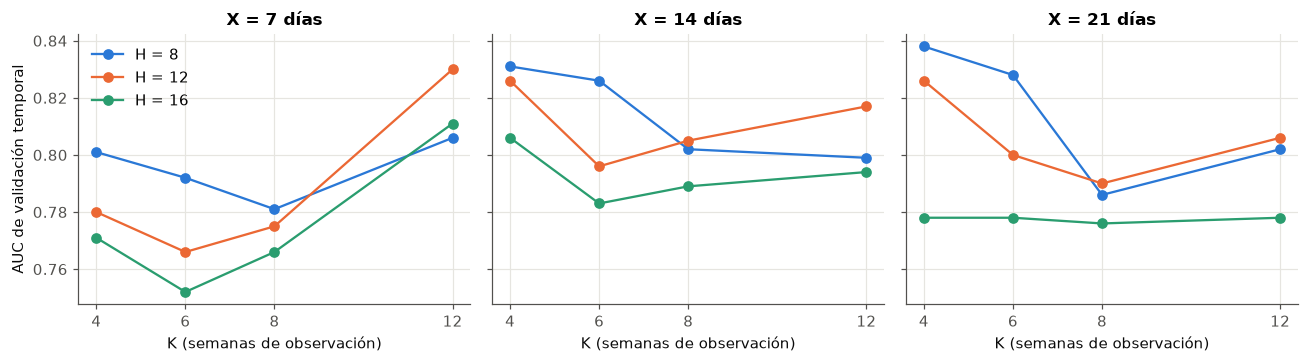

In [6]:
archivo_rejilla = DIR_SALIDA / "reports" / "rejilla_khx.csv"
if archivo_rejilla.exists():
    rejilla = pd.read_csv(archivo_rejilla)
else:
    filas = []
    for k in (4, 6, 8, 12):
        for h in (8, 12, 16):
            for x in (7, 14, 21):
                dat = construir_dataset(ep, ciclos, pagos, diario, CORTE, INICIO_COHORTE, k, h, x)
                if dat.y.nunique() < 2 or len(dat) < 300:
                    continue
                r = evaluar(armar(LogisticRegression(C=0.5, max_iter=2000, class_weight="balanced"), True, True, SEMILLA),
                            dat, COLS, k, h, x)
                filas.append({"K": k, "H": h, "X": x, "episodios": len(dat), "% positivos": round(100 * dat.y.mean(), 1),
                              "n prueba": r["n_prueba"], "AUC validación": round(r["auc_validacion"], 3),
                              "AUC prueba": round(r["prueba"]["AUC"], 3), "BACC prueba": round(r["prueba"]["BACC"], 3),
                              "MCC prueba": round(r["prueba"]["MCC"], 3)})
    rejilla = pd.DataFrame(filas)
    rejilla.to_csv(archivo_rejilla, index=False)
display(rejilla)
CIFRAS["rejilla"] = rejilla.to_dict(orient="records")

fig, ax = plt.subplots(1, 3, figsize=(12, 3.4), sharey=True)
for a, x in zip(ax, (7, 14, 21)):
    for h, col in zip((8, 12, 16), (AZUL, NARANJA, VERDE)):
        s = rejilla[(rejilla.X == x) & (rejilla.H == h)].sort_values("K")
        a.plot(s.K, s["AUC validación"], marker="o", color=col, label=f"H = {h}")
    a.set_title(f"X = {x} días"); a.set_xlabel("K (semanas de observación)"); a.set_xticks([4, 6, 8, 12])
ax[0].set_ylabel("AUC de validación temporal"); ax[0].legend(frameon=False)
fig.tight_layout(); fig.savefig(DIR_FIG / "rejilla_khx.png"); plt.show()

**Lectura.** Tres hallazgos, a leer con las precauciones indicadas arriba:

- **Se predice igual de bien con menos historial.** Con el mismo horizonte y atraso
  (*H* = 8, *X* = 14), *K* = 4 semanas alcanza un AUC de validación de 0,831 frente a 0,802
  con *K* = 8 y 0,799 con *K* = 12. Esperar más semanas no mejora la predicción en validación
  y retrasa la alerta. La población no es la misma (con *K* = 4 hay más episodios porque
  entran los que se cierran antes de la semana 8), por lo que se interpreta como una
  tendencia y no como una comparación exacta.
- **Cuanto más lejos el horizonte, peor.** Con *H* = 16 el AUC de validación suele ser menor
  que con *H* = 8 en la misma *K* y *X*.
- **La prueba con *K* = 12 es engañosa.** Su AUC de prueba es el más alto (hasta 0,85) pero
  la población de prueba es otra (solo episodios que sobreviven 12 semanas) y es pequeña
  (≈ 500 episodios); el intervalo de confianza del modelo base en prueba (sección 6) mide
  cerca de ± 0,04, así que diferencias de 0,03 o menos no son concluyentes.

Para la definición del estudio se mantiene *K* = 8, *H* = 12 y *X* = 14, fijada antes de
explorar. Los resultados de esta sección sugieren evaluar con el equipo de negocio si una
alerta a las 4 semanas, que es más temprana, es operativamente más valiosa.

## 6. Modelo final y evaluación en prueba

Se toma el modelo con mayor AUC de validación (sección 2) y se evalúa **una sola vez** en
la prueba temporal, con el umbral elegido en validación. Se acompaña de un intervalo de
confianza del 95 % por *bootstrap* sobre los episodios de prueba.

Regresión logística: AUC en prueba = 0.756  (IC 95 %: 0.716 – 0.794)
{'AUC': 0.756, 'F1 (clase 0)': 0.747, 'F1 (clase 1)': 0.619, 'BACC': np.float64(0.686), 'G-mean': 0.684, 'MCC': 0.367, 'exactitud': np.float64(0.696)} | umbral = 0.29


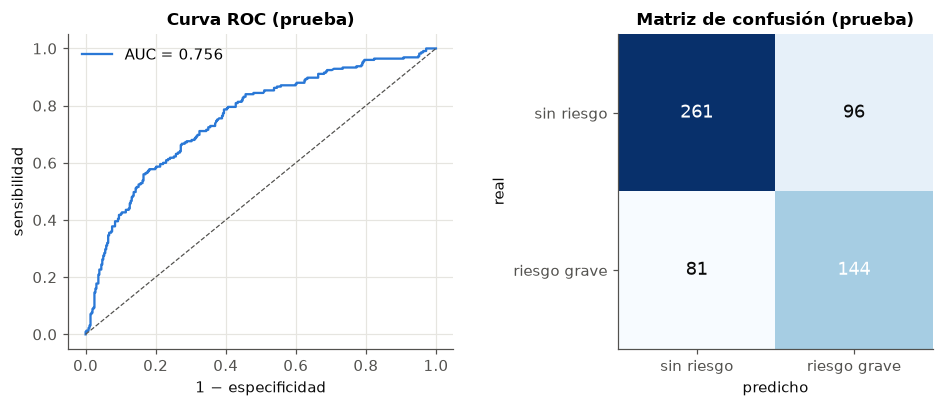

In [7]:
r = resultados[MEJOR]
y_te, p_te, u = r["y_prueba"], r["p_prueba"], r["umbral"]
rng = np.random.default_rng(SEMILLA)
from sklearn.metrics import roc_auc_score
boot = []
for _ in range(1000):
    idx = rng.integers(0, len(y_te), len(y_te))
    if len(np.unique(y_te[idx])) > 1:
        boot.append(roc_auc_score(y_te[idx], p_te[idx]))
ic = np.percentile(boot, [2.5, 97.5])
print(f"{MEJOR}: AUC en prueba = {r['prueba']['AUC']:.3f}  (IC 95 %: {ic[0]:.3f} – {ic[1]:.3f})")
print({k: round(v, 3) for k, v in r["prueba"].items()}, "| umbral =", round(u, 2))
CIFRAS["modelo_final"] = {"modelo": MEJOR, "umbral": u, "prueba": r["prueba"], "auc_ic95": ic.tolist()}

fig, ax = plt.subplots(1, 2, figsize=(9, 3.8))
fpr, tpr, _ = roc_curve(y_te, p_te)
ax[0].plot(fpr, tpr, color=AZUL, label=f"AUC = {r['prueba']['AUC']:.3f}")
ax[0].plot([0, 1], [0, 1], color=TINTA_2, ls="--", lw=0.8)
ax[0].set_xlabel("1 − especificidad"); ax[0].set_ylabel("sensibilidad"); ax[0].set_title("Curva ROC (prueba)")
ax[0].legend(frameon=False)
cm = confusion_matrix(y_te, (p_te >= u).astype(int))
ax[1].imshow(cm, cmap="Blues")
for (i, j), v in np.ndenumerate(cm):
    ax[1].text(j, i, v, ha="center", va="center", color="white" if v > cm.max() / 2 else TINTA, fontsize=12)
ax[1].set_xticks([0, 1]); ax[1].set_yticks([0, 1]); ax[1].set_xticklabels(["sin riesgo", "riesgo grave"])
ax[1].set_yticklabels(["sin riesgo", "riesgo grave"]); ax[1].grid(False)
ax[1].set_xlabel("predicho"); ax[1].set_ylabel("real"); ax[1].set_title("Matriz de confusión (prueba)")
fig.tight_layout(); fig.savefig(DIR_FIG / "modelo_final.png"); plt.show()

**Lectura.** El modelo base logra un AUC de aproximadamente 0,76 en el periodo más reciente
(intervalo de confianza del 95 %: 0,72 a 0,79), con una exactitud balanceada de 0,69 y un F1
de 0,62 para la clase de riesgo grave. Es un desempeño moderado pero útil como filtro de
priorización de cobro, y es el que se obtiene al validar en las condiciones del uso real
(predecir el futuro con datos del pasado). El AUC cercano a 0,81 de la prueba rápida con
partición aleatoria era optimista porque mezclaba periodos.

In [8]:
(DIR_SALIDA / "reports" / "cifras_clasificacion.json").write_text(
    json.dumps(CIFRAS, indent=2, ensure_ascii=False, default=lambda o: float(o) if hasattr(o, "item") else str(o)),
    encoding="utf-8")
print("Resultados guardados en", DIR_SALIDA / "reports")

Resultados guardados en C:\Users\LeNoVo\Documents\proyecto_modelos_2\reports
